# Placement prediction: analysis

Goal: predict `placed` (1 = received an offer through the placement cell) for a new list of registered students.
The metric is **F1 for `placed = 1`**.

The notebook covers:
1. **EDA**: data quality, how each feature relates to placement, missing values, and the `status_code` column.
2. **Modelling**: feature choices, model comparison, threshold tuning, and the final saved model(s).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

df = pd.read_csv("data/train.csv")
print(df.shape)
df.head()

(2500, 11)


,student_id,department,city_tier,cgpa,backlogs,internship_months,coding_score,projects,workshops,status_code,placed
0,S00802,CSE,2,7.00,1.0,5,56.6,5,4,NaN,1
1,S02107,CSE,3,8.06,1.0,4,29.9,1,3,1.0,1
2,S01945,CSE,3,7.92,0.0,0,52.4,2,2,0.0,0
3,S01956,MECH,2,7.49,1.0,1,37.3,1,1,0.0,0
4,S01828,CSE,2,8.80,NaN,0,82.2,2,3,1.0,1


## 1. EDA
### 1.1 Basic structure and data quality

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   student_id         2500 non-null   object 
 1   department         2500 non-null   object 
 2   city_tier          2500 non-null   int64  
 3   cgpa               2382 non-null   float64
 4   backlogs           2332 non-null   float64
 5   internship_months  2500 non-null   int64  
 6   coding_score       1975 non-null   float64
 7   projects           2500 non-null   int64  
 8   workshops          2500 non-null   int64  
 9   status_code        2387 non-null   float64
 10  placed             2500 non-null   int64  
dtypes: float64(4), int64(5), object(2)
memory usage: 215.0+ KB


In [3]:
summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(1),
    "n_unique": df.nunique(),
    "min": df.min(numeric_only=True),
    "max": df.max(numeric_only=True),
})
summary

,dtype,missing,missing_%,n_unique,min,max
backlogs,float64,168,6.7,7,0.0,6.0
cgpa,float64,118,4.7,406,5.0,10.0
city_tier,int64,0,0.0,3,1.0,3.0
coding_score,float64,525,21.0,647,5.2,100.0
department,object,0,0.0,6,NaN,NaN
internship_months,int64,0,0.0,7,0.0,6.0
placed,int64,0,0.0,2,0.0,1.0
projects,int64,0,0.0,11,0.0,10.0
status_code,float64,113,4.5,2,0.0,1.0
student_id,object,0,0.0,2500,NaN,NaN


In [4]:
print("Duplicate student_id:", df.student_id.duplicated().sum())
feat = df.drop(columns="student_id")
dups = df[feat.duplicated(keep=False)]
print("Rows identical apart from student_id:", len(dups))
dups

Duplicate student_id: 0
Rows identical apart from student_id: 2


,student_id,department,city_tier,cgpa,backlogs,internship_months,coding_score,projects,workshops,status_code,placed
536,S02003,CSE,3,NaN,1.0,0,NaN,1,4,0.0,0
912,S02454,CSE,3,NaN,1.0,0,NaN,1,4,0.0,0


In [5]:
# Range checks: is any value impossible?
checks = {
    "cgpa outside [0, 10]": (~df.cgpa.between(0, 10) & df.cgpa.notna()).sum(),
    "coding_score outside [0, 100]": (~df.coding_score.between(0, 100) & df.coding_score.notna()).sum(),
    "negative backlogs/projects/workshops/internship": (df[["backlogs", "projects", "workshops", "internship_months"]] < 0).sum().sum(),
    "cgpa == 10 (ceiling)": (df.cgpa == 10).sum(),
    "coding_score == 100 (ceiling)": (df.coding_score == 100).sum(),
    "non-integer backlogs": ((df.backlogs.dropna() % 1) != 0).sum(),
}
pd.Series(checks, name="count")

cgpa outside [0, 10]                               0
coding_score outside [0, 100]                      0
negative backlogs/projects/workshops/internship    0
cgpa == 10 (ceiling)                               1
coding_score == 100 (ceiling)                      3
non-integer backlogs                               0
Name: count, dtype: int64

In [6]:
print("Placement rate:", round(df.placed.mean(), 4))
df.placed.value_counts()

Placement rate: 0.2808


placed
0    1798
1     702
Name: count, dtype: int64

**Data quality findings**
- 2,500 rows and one row per student; no `student_id` appears twice.
- About 28% of students were placed. The classes are imbalanced, so a 0.5 cut-off will probably be too high for F1. The threshold gets tuned later.
- Missing values: `coding_score` (21%), `backlogs` (6.7%), `cgpa` (4.7%), `status_code` (4.5%). The README says the scoring file can also have empty cells, so the pipeline must handle NaN in **any** column, not only these four.
- All values are in plausible ranges (CGPA 5–10, coding score 5–100, no negative counts). Two rows are identical apart from their id. That is too few to matter, so both stay.

### 1.2 Feature distributions

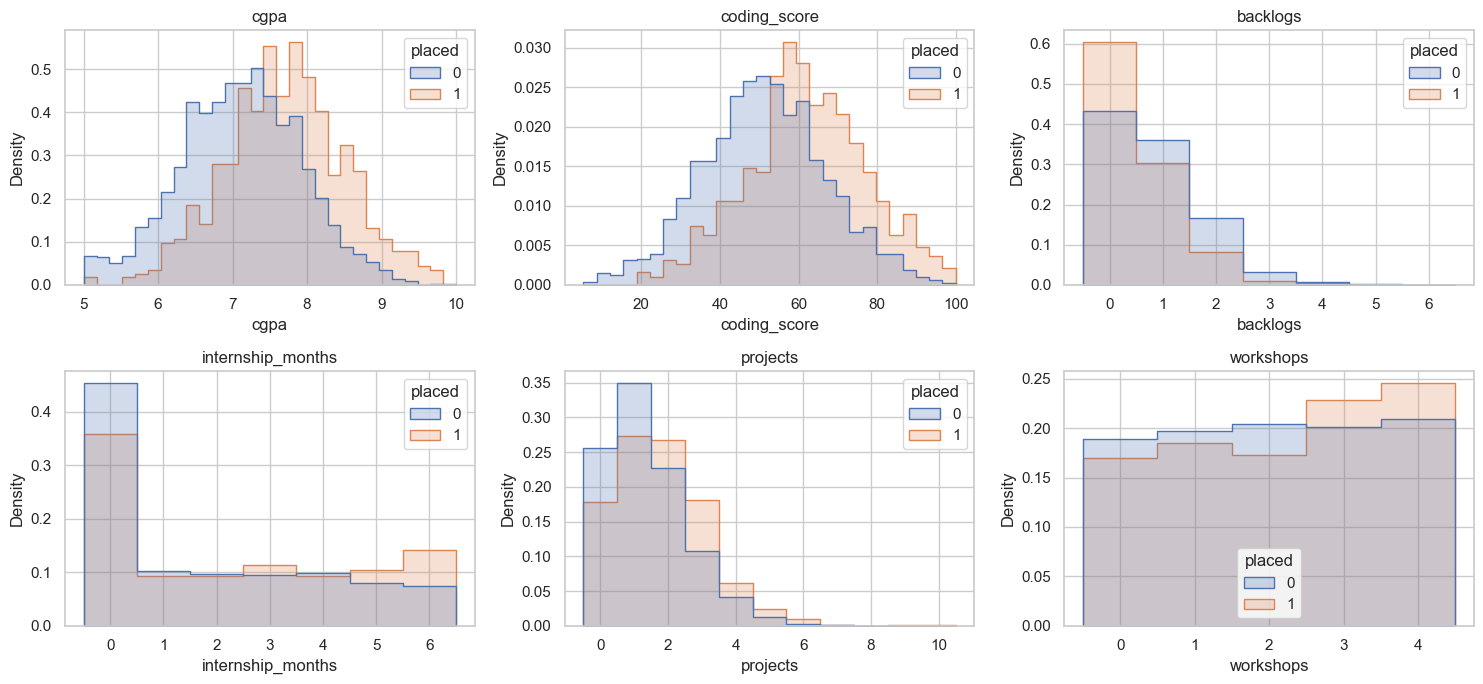

In [7]:
num_cols = ["cgpa", "coding_score", "backlogs", "internship_months", "projects", "workshops"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, c in zip(axes.flat, num_cols):
    sns.histplot(data=df, x=c, hue="placed", stat="density", common_norm=False, element="step",
                 discrete=c not in ("cgpa", "coding_score"), ax=ax)
    ax.set_title(c)
plt.tight_layout()

### 1.3 Placement rate by feature

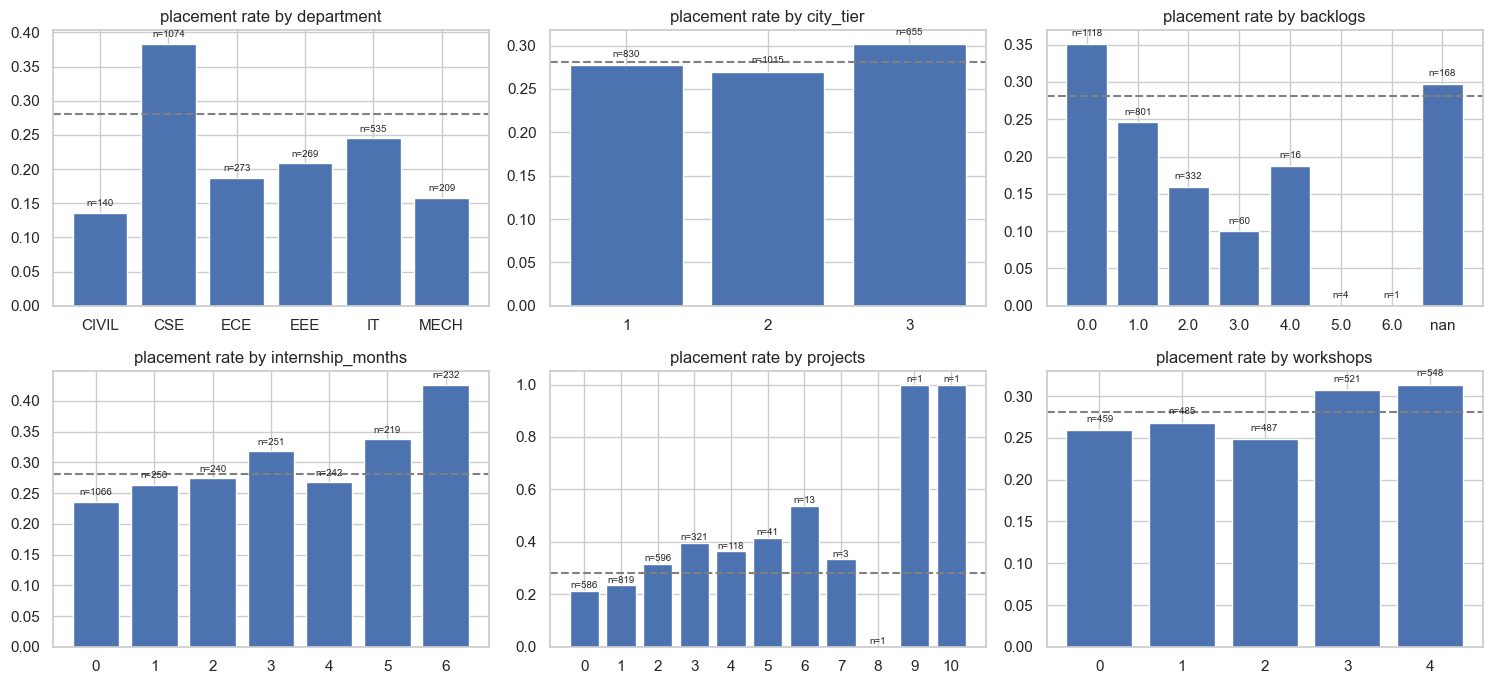

In [8]:
disc = ["department", "city_tier", "backlogs", "internship_months", "projects", "workshops"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, c in zip(axes.flat, disc):
    g = df.groupby(c, dropna=False).placed.agg(["mean", "count"]).reset_index()
    g[c] = g[c].astype(str)
    ax.bar(g[c], g["mean"])
    for x, (m, n) in enumerate(zip(g["mean"], g["count"])):
        ax.text(x, m + 0.01, f"n={n}", ha="center", fontsize=7)
    ax.axhline(df.placed.mean(), ls="--", c="grey")
    ax.set_title(f"placement rate by {c}")
plt.tight_layout()

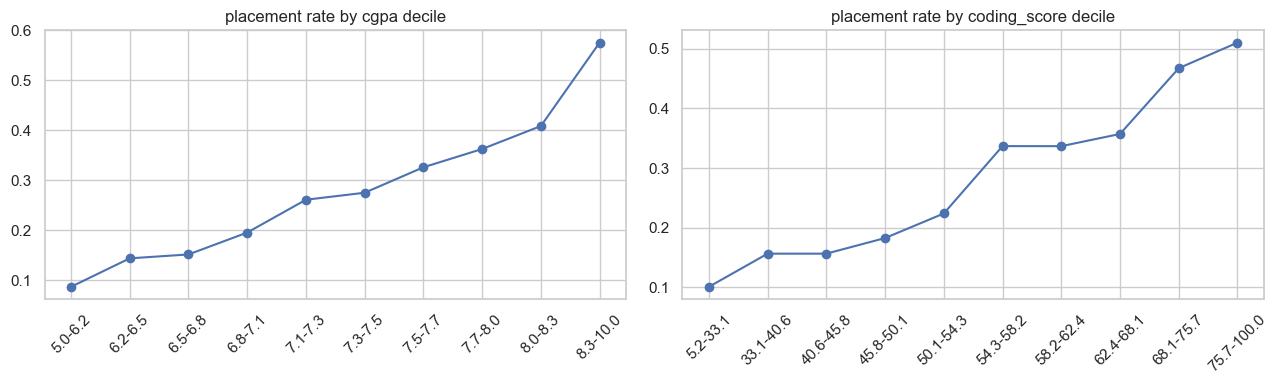

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, c in zip(axes, ["cgpa", "coding_score"]):
    bins = pd.qcut(df[c], 10)
    r = df.groupby(bins, observed=True).placed.mean()
    ax.plot(range(len(r)), r.values, marker="o")
    ax.set_xticks(range(len(r)), [f"{i.left:.1f}-{i.right:.1f}" for i in r.index], rotation=45)
    ax.set_title(f"placement rate by {c} decile")
plt.tight_layout()

In [10]:
# Does the department effect survive controlling for CGPA / coding score?
df.groupby("department")[["cgpa", "coding_score", "internship_months", "projects"]].mean().round(2).join(
    df.groupby("department").placed.mean().rename("placed_rate").round(3))

,cgpa,coding_score,internship_months,projects,placed_rate
department,,,,,
CIVIL,7.25,55.14,2.22,1.50,0.136
CSE,7.29,54.27,2.00,1.52,0.384
ECE,7.29,55.01,1.92,1.45,0.187
EEE,7.34,53.97,1.94,1.41,0.208
IT,7.20,53.47,1.90,1.52,0.245
MECH,7.32,55.36,1.96,1.65,0.158


**Feature findings**
- **CGPA** and **coding score** have the strongest effects, and both rise steadily: about 10% placed in the lowest decile versus about 50% or more in the highest.
- **Department** matters on its own. CSE is placed at 38%, CIVIL and MECH at about 14–16%. Average CGPA and coding score are similar across departments, so the gap is not just ability. Recruiters seem to prefer some branches.
- **Backlogs** reduce the chance of placement steadily (35% with none, 10% with three).
- **Internship months** and **projects** help a little, mostly at the top end (5–6 months, 3+ projects).
- **City tier** and **workshops** show almost no difference (27–31% across levels), so they will add little signal.

### 1.4 Missing values: random, or informative?

In [11]:
miss_cols = ["cgpa", "backlogs", "coding_score", "status_code"]
pd.DataFrame({c: df.groupby(df[c].isna()).placed.mean() for c in miss_cols}).T.rename(
    columns={False: "rate_when_present", True: "rate_when_missing"}).join(df[miss_cols].isna().sum().rename("n_missing")).round(3)

,rate_when_present,rate_when_missing,n_missing
cgpa,0.277,0.347,118
backlogs,0.280,0.298,168
coding_score,0.283,0.274,525
status_code,0.284,0.212,113


In [12]:
# Do missing values cluster together, or by department?
print(df[miss_cols].isna().astype(int).corr().round(2))
df.assign(**{f"{c}_missing": df[c].isna() for c in miss_cols}).groupby("department")[[f"{c}_missing" for c in miss_cols]].mean().round(3)

              cgpa  backlogs  coding_score  status_code
cgpa          1.00       0.0          0.01        -0.02
backlogs      0.00       1.0         -0.00         0.00
coding_score  0.01      -0.0          1.00         0.00
status_code  -0.02       0.0          0.00         1.00


,cgpa_missing,backlogs_missing,coding_score_missing,status_code_missing
department,,,,
CIVIL,0.043,0.093,0.200,0.071
CSE,0.041,0.068,0.214,0.046
ECE,0.048,0.073,0.198,0.040
EEE,0.052,0.045,0.223,0.052
IT,0.064,0.075,0.185,0.045
MECH,0.033,0.048,0.258,0.024


**Missing-value findings**
- Missing values in different columns are uncorrelated with each other and spread evenly across departments.
- Placement rates are about the same whether a value is present or missing (for example, coding score: 28.3% vs 27.4%). The small gap for `cgpa` (34.7% vs 27.7%) comes from only 118 rows and is within noise.
- So the values look **missing at random**. Median imputation is reasonable. Missing-value indicator columns are cheap to add and the model can ignore them if useless.

### 1.5 Correlations

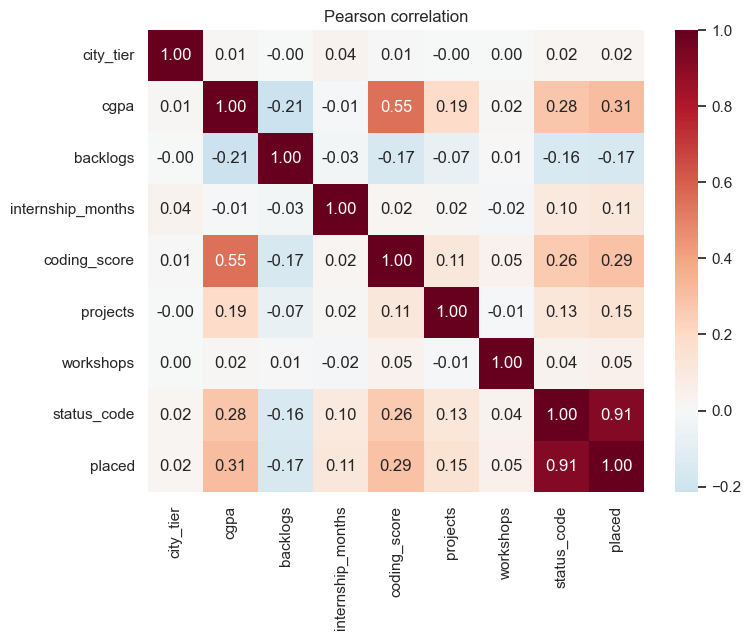

In [13]:
corr = df.drop(columns=["student_id", "department"]).corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Pearson correlation");

`cgpa` and `coding_score` are fairly correlated with each other (0.55), so they partly overlap. Every real feature has a modest correlation with `placed`, at most 0.31 (cgpa).
`status_code` correlates **0.91** with `placed`, which is far higher than everything else. The next section looks at it.

### 1.6 `status_code`: is it a leak?

In [14]:
pd.crosstab(df.status_code.fillna(-1).map({-1: "missing", 0: "0", 1: "1"}), df.placed, margins=True)

placed,0,1,All
status_code,,,
0,1654,33,1687
1,55,645,700
missing,89,24,113
All,1798,702,2500


In [15]:
from sklearn.metrics import f1_score, precision_score, recall_score
known = df.status_code.notna()
pred = df.loc[known, "status_code"].astype(int)
print("status_code used directly as the prediction (rows where it's known):")
print(f"  precision={precision_score(df.placed[known], pred):.3f}  "
      f"recall={recall_score(df.placed[known], pred):.3f}  F1={f1_score(df.placed[known], pred):.3f}")

status_code used directly as the prediction (rows where it's known):
  precision=0.921  recall=0.951  F1=0.936


In [16]:
# If status_code were an input (e.g. 'eligible'), it would depend on cgpa/backlogs in its own way.
# If it records the outcome, its groups should look exactly like the placed groups.
prof = pd.concat({
    "status_code=0": df[df.status_code == 0],
    "status_code=1": df[df.status_code == 1],
    "placed=0": df[df.placed == 0],
    "placed=1": df[df.placed == 1],
}, names=["group"]).groupby("group")[["cgpa", "coding_score", "backlogs", "internship_months", "projects"]].mean().round(2)
prof

,cgpa,coding_score,backlogs,internship_months,projects
group,,,,,
placed=0,7.11,51.30,0.83,1.82,1.39
placed=1,7.70,61.85,0.51,2.37,1.81
status_code=0,7.13,51.56,0.83,1.84,1.41
status_code=1,7.65,60.91,0.53,2.30,1.77


**`status_code` findings**
- When it is 1, 92% of students were placed. When it is 0, only 2% were. Used directly as the prediction, it gets **F1 ≈ 0.94**, which no real feature comes near.
- The students with `status_code = 1` look just like the students with `placed = 1` (same average CGPA, coding score and backlogs). The column behaves like a **copy of the outcome**, not like an input that explains it.
- The README calls it only "a field stored on the placement portal". Portal status fields such as *offer received*, *accepted* or *closed* are usually updated **after** the placement process. At the time we want to predict (a fresh list of registered students), that value would not exist yet.
- Conclusion: `status_code` is almost certainly **target leakage**. A model that uses it isn't predicting placement; it's reading a recorded outcome.

**What I do with it:** the main model **excludes** `status_code`. The scoring file is said to have the same columns, so I also train a second model that uses it, to show what it is worth. `predict.py` uses the leak-free model by default; the other one is available only behind an explicit flag.

### 1.7 EDA summary → modelling decisions
| Finding | Decision |
| --- | --- |
| 28% positive class, F1 metric | Tune the decision threshold with cross-validation; don't use 0.5 |
| Missing values look random, and any cell in the scoring file may be empty | Median/most-frequent imputation inside the pipeline, plus missing-value indicators, for **every** column |
| CGPA, coding score, backlogs and department carry the signal; trends are mostly smooth | A linear model should do well; compare it with tree ensembles |
| `city_tier` and `workshops` show little signal | Keep them (cheap), and check whether dropping them changes the CV score |
| `status_code` is effectively the label | Leave it out of the main model; train a separate "with status_code" model only for comparison |
| `student_id` is just an identifier | Not used as a feature |

## 2. Modelling
### 2.1 Setup
`predict.py` defines `prepare()`, the one function that cleans raw rows for **both** training and scoring. It adds any missing column as empty, turns unreadable numbers into NaN, and normalises department names. That way training and scoring prepare data exactly the same way.

In [17]:
import warnings
warnings.filterwarnings("ignore")
import joblib, sklearn
from sklearn.base import clone
from sklearn.compose import make_column_transformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, confusion_matrix
from sklearn.model_selection import RepeatedStratifiedKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, SplineTransformer, StandardScaler

from predict import prepare

X_all = prepare(df)
y = df.placed.values

BASE = ["city_tier", "cgpa", "backlogs", "internship_months", "coding_score", "projects", "workshops"]
WITH_STATUS = BASE + ["status_code"]

In [18]:
dept_enc = lambda: make_pipeline(SimpleImputer(strategy="most_frequent"),
                                 OneHotEncoder(handle_unknown="ignore", sparse_output=False))

def logreg(num, C=1.0, spline=False, interactions=False):
    num_steps = ([SimpleImputer(strategy="median"), SplineTransformer(n_knots=4)] if spline
                 else [SimpleImputer(strategy="median", add_indicator=True), StandardScaler()])
    steps = [make_column_transformer((make_pipeline(*num_steps), num), (dept_enc(), ["department"]))]
    if interactions:
        steps += [PolynomialFeatures(2, interaction_only=True, include_bias=False), StandardScaler()]
    return make_pipeline(*steps, LogisticRegression(C=C, max_iter=5000))

def trees(num, model):
    # Tree models handle NaN natively (HGB) or via imputation (RF)
    numeric = "passthrough" if isinstance(model, HistGradientBoostingClassifier) else SimpleImputer(strategy="median", add_indicator=True)
    return make_pipeline(make_column_transformer((numeric, num), (dept_enc(), ["department"])), model)

### 2.2 Evaluation protocol
- **Repeated stratified 5-fold CV (3 repeats, 15 fits)**. One 5-fold split is noisy on 2,500 rows, and models differ by only a few hundredths of F1.
- Each repeat gives a full set of out-of-fold probabilities. I sweep the threshold, average the F1 curve over the repeats, and report the **best average F1 and its threshold**. The metric is F1, so the threshold is part of the model.
- Baseline: predicting "placed" for everyone gives F1 = 2·0.28/1.28 ≈ **0.44**. Any useful model has to beat that.

In [19]:
THRESHOLDS = np.round(np.arange(0.10, 0.80, 0.01), 2)

def oof_probs(model, features, X=X_all, y=y, n_repeats=3, seed=42):
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=n_repeats, random_state=seed)
    oof = np.zeros((n_repeats, len(y)))
    for i, (tr, te) in enumerate(cv.split(X, y)):
        m = clone(model).fit(X.iloc[tr], y[tr])
        oof[i // 5, te] = m.predict_proba(X.iloc[te])[:, 1]
    return oof

def f1_curve(oof, y=y):
    # F1 at each threshold, averaged over repeats (vectorised)
    curves = []
    for p in oof:
        pred = p[None, :] >= THRESHOLDS[:, None]
        tp = (pred & (y == 1)).sum(1); fp = (pred & (y == 0)).sum(1); fn = ((~pred) & (y == 1)).sum(1)
        curves.append(2 * tp / np.maximum(2 * tp + fp + fn, 1))
    return np.mean(curves, axis=0)

def evaluate(model, features):
    oof = oof_probs(model, features)
    curve = f1_curve(oof)
    best = curve.argmax()
    return {"cv_auc": np.mean([roc_auc_score(y, p) for p in oof]),
            "f1_at_0.5": curve[np.where(THRESHOLDS == 0.5)[0][0]],
            "best_f1": curve[best], "threshold": THRESHOLDS[best]}, curve

In [20]:
NO_TIER_WS = [c for c in BASE if c not in ("city_tier", "workshops")]
candidates = {
    "logreg C=1":                        (logreg(BASE, C=1.0), BASE),
    "logreg C=0.1":                      (logreg(BASE, C=0.1), BASE),
    "logreg C=0.03":                     (logreg(BASE, C=0.03), BASE),
    "logreg splines":                    (logreg(BASE, C=0.1, spline=True), BASE),
    "logreg pairwise interactions":      (logreg(BASE, C=0.05, interactions=True), BASE),
    "logreg w/o city_tier, workshops":   (logreg(NO_TIER_WS, C=1.0), NO_TIER_WS),
    "hist gradient boosting":            (trees(BASE, HistGradientBoostingClassifier(max_depth=2, learning_rate=0.03, max_iter=300, min_samples_leaf=40, random_state=0)), BASE),
    "random forest":                     (trees(BASE, RandomForestClassifier(400, min_samples_leaf=10, random_state=0, n_jobs=-1)), BASE),
    "[status_code] logreg C=1":          (logreg(WITH_STATUS, C=1.0), WITH_STATUS),
    "[status_code] hist grad boosting":  (trees(WITH_STATUS, HistGradientBoostingClassifier(max_depth=2, learning_rate=0.05, max_iter=200, min_samples_leaf=40, random_state=0)), WITH_STATUS),
}
results, curves = {}, {}
for name, (model, feats) in candidates.items():
    results[name], curves[name] = evaluate(model, feats)
pd.DataFrame(results).T.round(3)

,cv_auc,f1_at_0.5,best_f1,threshold
logreg C=1,0.766,0.448,0.566,0.25
logreg C=0.1,0.766,0.430,0.562,0.26
logreg C=0.03,0.764,0.402,0.560,0.28
logreg splines,0.766,0.381,0.569,0.28
logreg pairwise interactions,0.743,0.447,0.545,0.24
"logreg w/o city_tier, workshops",0.766,0.445,0.563,0.31
hist gradient boosting,0.755,0.424,0.555,0.29
random forest,0.754,0.385,0.566,0.31
[status_code] logreg C=1,0.975,0.922,0.924,0.56
[status_code] hist grad boosting,0.972,0.918,0.920,0.58


**Model comparison**
- Every model **without** `status_code` scores CV F1 between 0.55 and 0.57. The differences are about the size of the noise between CV repeats. Splines, interactions, gradient boosting and random forests add nothing over plain logistic regression, which matches the smooth, roughly additive trends from the EDA.
- Dropping `city_tier` and `workshops` changes almost nothing, as the EDA predicted. I keep them, because removing them gains nothing and they cost nothing.
- **Chosen model: logistic regression (C=1) with a tuned threshold.** It is as accurate as the alternatives, is the simplest, its coefficients can be read directly (section 2.5), and it is least likely to overfit a fresh list.
- With `status_code`, every model reaches about 0.92. That jump comes almost entirely from the leaked column (section 1.6).
- Tuning the threshold matters: at the default 0.5 cut-off the leak-free model scores much lower F1, because only about 28% of students are positive.

### 2.3 Threshold choice

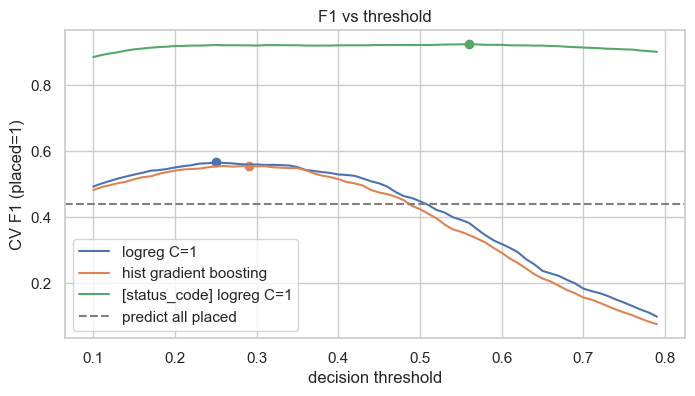

In [21]:
fig, ax = plt.subplots(figsize=(8, 4))
for name in ["logreg C=1", "hist gradient boosting", "[status_code] logreg C=1"]:
    ax.plot(THRESHOLDS, curves[name], label=name)
    ax.scatter(results[name]["threshold"], results[name]["best_f1"])
ax.axhline(2 * y.mean() / (1 + y.mean()), ls="--", c="grey", label="predict all placed")
ax.set_xlabel("decision threshold"); ax.set_ylabel("CV F1 (placed=1)"); ax.legend(); ax.set_title("F1 vs threshold");

The leak-free F1 curve is flat near its peak: anywhere between about 0.20 and 0.30, F1 stays within about 0.015 of the best value, so the exact threshold isn't critical. The chosen value comes from CV out-of-fold predictions, never from the rows the final model was fitted on.

### 2.4 Holdout check
As a final honesty check, I set aside 20% of the data. On the remaining 80% I repeat the whole procedure (CV to pick the threshold, then fit), and then score the untouched 20% once.

In [22]:
idx_tr, idx_te = train_test_split(np.arange(len(y)), test_size=0.2, stratify=y, random_state=7)
rows = {}
for name, feats in [("logreg C=1", BASE), ("[status_code] logreg C=1", WITH_STATUS)]:
    model = candidates[name][0]
    Xtr, ytr = X_all.iloc[idx_tr], y[idx_tr]
    t = THRESHOLDS[f1_curve(oof_probs(model, feats, Xtr, ytr), ytr).argmax()]
    fitted = clone(model).fit(Xtr, ytr)
    pred = (fitted.predict_proba(X_all.iloc[idx_te])[:, 1] >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y[idx_te], pred).ravel()
    rows[name] = {"threshold": t, "precision": tp / (tp + fp), "recall": tp / (tp + fn),
                  "f1": 2 * tp / (2 * tp + fp + fn), "tp": tp, "fp": fp, "fn": fn, "tn": tn}
pd.DataFrame(rows).T.round(3)

,threshold,precision,recall,f1,tp,fp,fn,tn
logreg C=1,0.26,0.467,0.757,0.578,106.0,121.0,34.0,239.0
[status_code] logreg C=1,0.50,0.893,0.957,0.924,134.0,16.0,6.0,344.0


The holdout F1 is close to the CV estimate, so that estimate is a fair guess of performance on the separate list. The leak-free model trades precision for recall: it flags more students than are actually placed to catch most real placements, which is the trade-off F1 rewards when the positive class is about 28% of students.

### 2.5 What the model learned

,coef
department_CIVIL,-0.611
department_MECH,-0.459
backlogs,-0.293
department_ECE,-0.154
department_EEE,-0.043
missingindicator_backlogs,0.038
missingindicator_coding_score,0.040
city_tier,0.040
workshops,0.082
missingindicator_cgpa,0.096


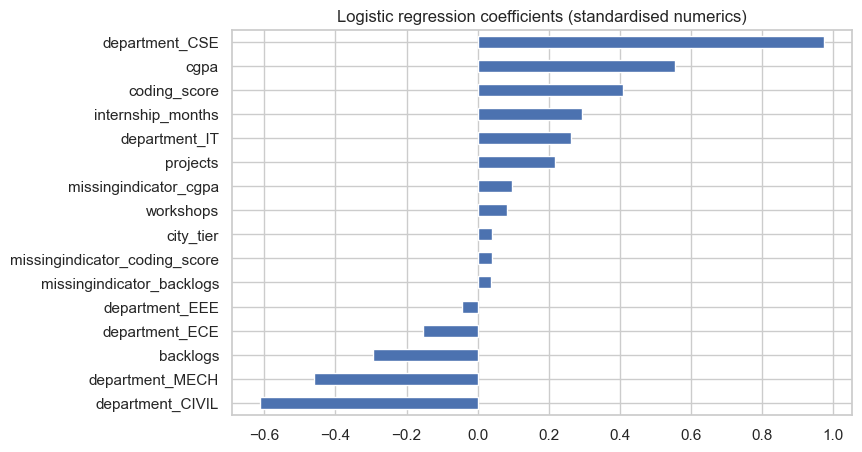

In [23]:
final_base = clone(candidates["logreg C=1"][0]).fit(X_all, y)
names = [n.split("__", 1)[1] for n in final_base[:-1].get_feature_names_out()]
coef = pd.Series(final_base[-1].coef_[0], index=names).sort_values()
plt.figure(figsize=(8, 5)); coef.plot.barh(); plt.title("Logistic regression coefficients (standardised numerics)");
coef.round(3).to_frame("coef")

The coefficients agree with the EDA: CGPA and coding score push placement up most, backlogs push it down, and CSE (then IT) has a clear department advantage over CIVIL and MECH. Internships and projects add a little. City tier, workshops and the missing-value indicators are close to zero.

### 2.6 Train and save the final models
Both models are fitted on **all** 2,500 rows, using the thresholds picked by CV in section 2.2.
- `model.joblib`: **default**, no `status_code`.
- `model_with_status_code.joblib`: used only with `python predict.py --use-status-code`.

In [24]:
bundles = {
    "model.joblib": ("logreg C=1", BASE),
    "model_with_status_code.joblib": ("[status_code] logreg C=1", WITH_STATUS),
}
for fname, (name, feats) in bundles.items():
    pipe = clone(candidates[name][0]).fit(X_all, y)
    joblib.dump({"pipeline": pipe, "features": feats + ["department"], "threshold": float(results[name]["threshold"]),
                 "cv_f1": float(results[name]["best_f1"]), "sklearn_version": sklearn.__version__}, fname)
    print(f"{fname}: threshold={results[name]['threshold']:.2f}  CV F1={results[name]['best_f1']:.3f}")

model.joblib: threshold=0.25  CV F1=0.566
model_with_status_code.joblib: threshold=0.56  CV F1=0.924


### 2.7 Smoke test of `predict.py`
The scoring file "can have empty cells". This test runs `predict.py` on rows that are blank, entirely empty, have a missing column, an unseen department and junk values, and checks the output format.

In [25]:
import subprocess, sys, tempfile, os
messy = df.drop(columns="placed").sample(200, random_state=1).reset_index(drop=True)
rng = np.random.default_rng(0)
for c in ["department", "city_tier", "cgpa", "backlogs", "internship_months", "coding_score", "projects", "status_code"]:
    messy.loc[rng.random(len(messy)) < 0.15, c] = np.nan             # random empty cells in every column
messy = messy.drop(columns="workshops")                               # a whole column missing
messy["department"] = messy["department"].astype(object)
messy.loc[0, "department"] = "AI&DS"                                  # department never seen in training
messy.loc[1, "department"] = " cse "                                  # messy formatting
messy["cgpa"] = messy["cgpa"].astype(object); messy.loc[2, "cgpa"] = "n/a"   # junk value
messy.loc[3, messy.columns[1:]] = np.nan                              # a row with nothing but an id

with tempfile.TemporaryDirectory() as tmp:
    src, dst = os.path.join(tmp, "in.csv"), os.path.join(tmp, "out.csv")
    messy.to_csv(src, index=False)
    for extra in [[], ["--use-status-code"]]:
        r = subprocess.run([sys.executable, "predict.py", "--input", src, "--output", dst, *extra], capture_output=True, text=True)
        print(r.stdout.strip() or r.stderr)
        out = pd.read_csv(dst, dtype={"student_id": str})
        assert list(out.columns) == ["student_id", "placed"]
        assert out.student_id.tolist() == messy.student_id.tolist()
        assert set(out.placed.unique()) <= {0, 1}
print("all checks passed")

model.joblib: wrote 200 rows to C:\Users\prano\AppData\Local\Temp\tmp_7871sgc\out.csv (116 predicted placed, threshold 0.25)


model_with_status_code.joblib: wrote 200 rows to C:\Users\prano\AppData\Local\Temp\tmp_7871sgc\out.csv (53 predicted placed, threshold 0.56)
all checks passed


## 3. Summary
- **Data checks:** missing values, ranges, duplicates, class balance, how each feature relates to placement, whether missing values carry signal, and leakage.
- **Features used (default model):** department, city tier, CGPA, backlogs, internship months, coding score, projects, workshops, and missing-value indicators. `student_id` is an identifier only.
- **Feature excluded: `status_code`.** It reproduces the label (F1 ≈ 0.94 on its own, and the same student profile as `placed`). It is almost certainly written to the portal after the placement outcome, so it cannot be known for a fresh list of registered students. Using it would score well here only because the answer has leaked into the data.
- **Model:** median/most-frequent imputation with missing-value indicators, standardisation, one-hot department, logistic regression, and a decision threshold tuned for F1 with repeated CV. More complex models were no better.
- **Expected F1 on the new list:** about 0.56, against 0.44 for predicting everyone as placed. If the scoring file carries the same leaked `status_code`, `--use-status-code` gives about 0.92, but I would not trust that model in real use.
- **Limitations:** most of the variation in placement is not explained by these features (AUC about 0.77). Recruiter demand, interview performance and soft skills are not in the data, which caps what any model can do here.